# 01 · Preprocessing — Zhang 2019 Follicular Lymphoma (malignant compartment)

Isolate malignant B cells, threshold thin samples by a **data-driven multiplicative gap**, integrate
patients (Harmony on `sample`), embed, remove detached islands, then read **Gate 1** (sample-mixing +
manifold continuity) off the regenerated embedding *and* a per-neighbourhood metric (iLISI) across an
integration-strength sweep — never a scalar alone.

Zhang 2019 is follicular lymphoma profiled by 10x across **4 malignant samples from 2 patients**
(FL1018, FL2001), each sampled at two disease timepoints (primary / progressed / transformed-DLBCL).
FL is a germinal-centre-derived B-cell malignancy; malignant clones are strongly **patient-private**, so
raw patient segregation is expected and strong Harmony integration is required. A minor proliferative
(cell-cycle) compartment (~14% cycling) sits at one pole; it is identified here as a lobe and carried as
a declared caveat into 02, where the trajectory is scoped away from it (the developmental modules must
be read free of a proliferation confound). Every tunable choice is *derived from this dataset*, not
inherited from the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Zhang2019_Hematologic-4
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-4' re-analysis suffix
raw_name = 'Data_' + name.replace('-4','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Zhang2019_Hematologic-4 | category: Hematologic | raw: Data_Zhang2019_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total + `log1p`, and keeps
the publication `cell_type`. Zhang 2019 carries author annotations, so we keep the malignant call
(`celltype == 'Malignant'`, the publication's malignant B cells) and drop the normal T/B compartment.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs['cell_type'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('per-sample:', adata.obs['sample'].value_counts().to_dict())
print('progression:', adata.obs['progression_status'].value_counts().to_dict())
print('cell_cycle:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())

full atlas: (7002, 24410)
cell types: {'Malignant': 5645, 'T_cell': 843, 'B_cell': 494}
malignant: (5645, 24410) | samples: 4
per-sample: {'FL1018T2': 2405, 'FL2001T2': 1876, 'FL2001T1': 684, 'FL1018T1': 680}
progression: {'transformed (DLBCL)': 2405, 'progressed': 1876, 'primary': 1364}
cell_cycle: {'Not cycling': 4853, 'G1/S': 599, 'G2/M': 124, 'Intermediate': 69}
expression: X max 7.33 (log1p of normalize_total UMIcounts)


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the geometric mean of the largest **multiplicative** gap
(the natural separatrix between tumour-bearing samples and spillover). Here the largest gap ratio is
2.74 (1876→684) — not a clean count cliff, and the smallest sample (680) is a genuine *primary* FL
tumour, not spillover. The premise of the gap rule (a clean cliff) is **not met**, so no sample is
dropped (a ≥100 floor keeps all four; 680 ≫ floor).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh_gap = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'geometric-mean gap threshold = {thresh_gap}, but ratio {ratios[gap]:.2f} is not a clean cliff')
floor = 100
keep = n.index[n >= floor]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'applied >=100 floor -> kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (min sample {int(vals.min())})')

sorted per-sample counts: [2405 1876  684  680]
largest multiplicative gap: 1876 -> 684 (ratio 2.74)
geometric-mean gap threshold = 1132, but ratio 2.74 is not a clean cliff
applied >=100 floor -> kept 4/4 samples -> 5645 cells (min sample 680)


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates GAM), PCA, then Harmony on `sample`. `theta` is chosen by an
integration-strength sweep read on iLISI (effective #samples per neighbourhood). FL clones are strongly
patient-private (pre-Harmony iLISI ≈ 1.0 of 4), so the strongest theta is required. `n_pcs=20` and UMAP
`spread=1.3` follow the 10x precedents (Kürten/Sun/Lee/Neftel, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; n_samp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
print(f'pre-Harmony iLISI median = {il_pre:.2f} of {n_samp} (fully patient-segregated)')
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp))
print('theta sweep iLISI median (20 PC):', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing rises monotonically; strongest integration, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
pre-Harmony iLISI median = 1.00 of 4 (fully patient-segregated)
theta sweep iLISI median (20 PC): {2: np.float64(1.3), 5: np.float64(2.03), 10: np.float64(2.26)}
selected theta = 10 (mixing rises monotonically; strongest integration, no collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous body.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'connected components: {ncomp}; removing {int((lab!=main).sum())} cells in {ncomp-1} detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

connected components: 1; removing 0 cells in 0 detached islands
after island removal: (5645, 14715)


### Lobe identity — settle each sub-region's biology before the Gate-1 GO
Cluster the manifold (Leiden res 0.3) and score the three developmental modules + a proliferation score
so each lobe's identity is explicit. One lobe is **~95% cycling** (a proliferative pole); the rest is a
single low-cycling body. This proliferative lobe is where the pSom score is confounded by cell cycle
(quantified in 02), so 02 scopes the trajectory away from it. Identifying it here is the Kürten
lobe-identity requirement.

In [7]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
adata.obs['cyc_score'] = np.maximum(pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0),
                                    pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0))
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
prof = adata.obs.groupby('lobe', observed=True).agg(n=('lobe','size'), cyc_frac=('cycling','mean'),
        Gast=('Gast_sm','mean'), pSom=('pSom_sm','mean'), Crest=('Crest_sm','mean'), cyc_score=('cyc_score','mean'))
print(prof.round(4).to_string())
cyc_lobe = prof['cyc_frac'].idxmax()
adata.obs['compartment'] = np.where(adata.obs['lobe']==cyc_lobe, 'Cycling', 'Body')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print(f'cycling lobe = {cyc_lobe} ({int(prof.loc[cyc_lobe,"n"])} cells, {prof.loc[cyc_lobe,"cyc_frac"]*100:.0f}% cycling)')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
         n  cyc_frac    Gast    pSom   Crest  cyc_score
lobe                                                   
0     3156    0.0913  0.0089  0.0032  0.0128     0.1874
1     1444    0.1932  0.0107  0.0053  0.0135     0.3802
2      849    0.0448  0.0185  0.0044  0.0029     0.1223
3      196    0.9541  0.0017  0.0344 -0.0056     1.8734
cycling lobe = 3 (196 cells, 95% cycling)
compartments: {'Body': 5449, 'Cycling': 196}


### House orientation — one consistent horizontal layout for every UMAP
Rotate the raw joint embedding (rigid, distance-preserving — *not* a re-embedding) so its axis of
maximal variance is horizontal, with the **Gast-high developmental origin on the left** (pseudotime will
run left→right once fit in 02). Stored as `X_umap_lin`, re-used unchanged by 02/03/04 (binding: one
orientation across all deliverables).

In [8]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
# Gast-high (developmental origin) -> left (low x)
if np.average(xyr[:,0], weights=(adata.obs['Gast_sm'].values - adata.obs['Gast_sm'].min() + 1e-9)) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved), Gast-high origin on left')

manifold aspect (max/min std): 1.65
house orientation: rigid rotation +92.5deg (distances preserved), Gast-high origin on left


### Gate 1 — batch mixing & manifold continuity (read on the embedding + iLISI)
Samples must intermix (no per-patient island) on one continuous manifold. The read is made on the
regenerated embedding (below) *and* per-neighbourhood iLISI across the theta sweep — not a scalar alone.
Pre-Harmony iLISI ≈ 1 (fully segregated) rises to ≈ 2.3/4 at theta=10; the two patients and all four
samples overlap rather than forming separate islands, and a single connected component remains after
island removal. **Gate 1 = GO.**

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 2.26 of 4 samples; patient 1.67 of 2
4 samples / 2 patients share one continuous manifold (one connected component after island removal)
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


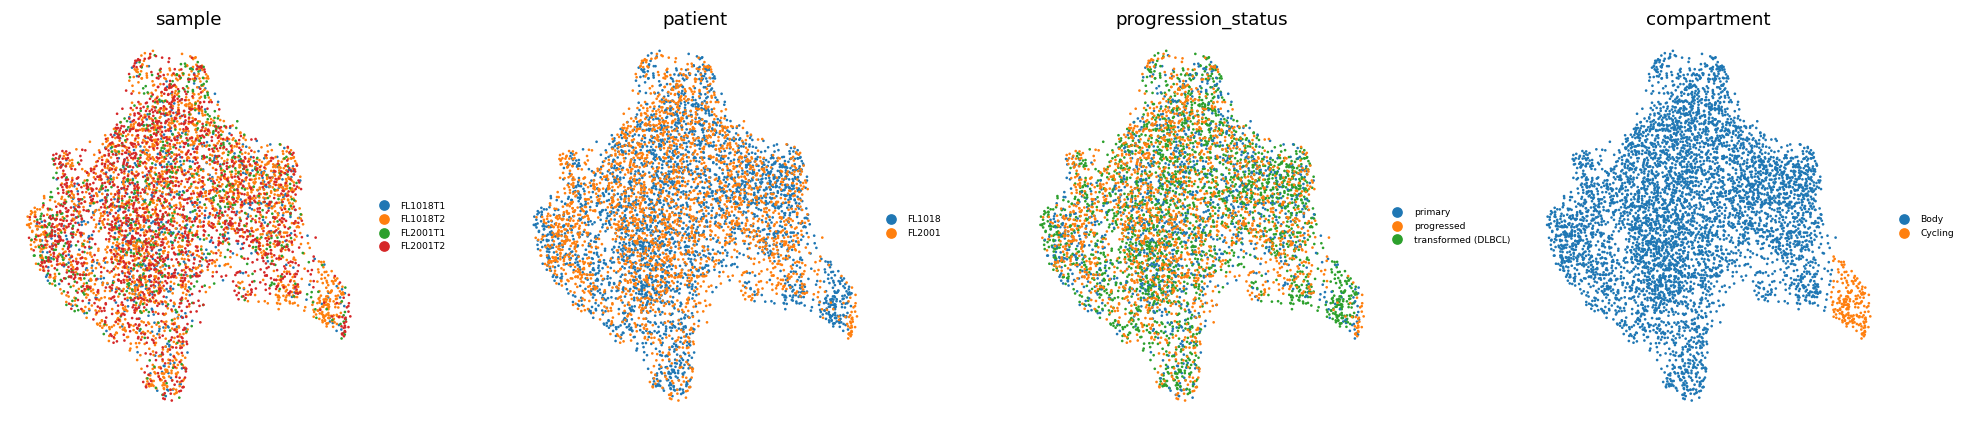

In [9]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
il_pat  = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['patient'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples; patient {il_pat:.2f} of 2')
print(f'{n_samp} samples / 2 patients share one continuous manifold (one connected component after island removal)')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax,col in zip(axes, ['sample','patient','progression_status','compartment']):
    sc.pl.umap(plot, color=col, size=12, frameon=False, show=False, ax=ax, legend_fontsize=6, title=col)
fig.tight_layout(); plt.show()

### Save processed data (full malignant manifold)

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum()>0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Sample-integration figure (deliverable) — house style `(3.5,1.5)` horizontal strip

saved samples.pdf | cells: 5645


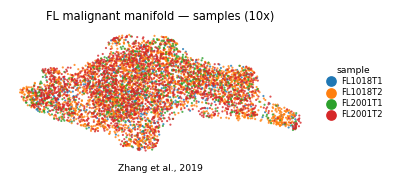

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('FL malignant manifold — samples (10x)', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])